# Projet : RSA jouet, et l'attaque qui le casse

**Module Outils fondamentaux — projet personnel.**

Ce projet construit un chiffrement **RSA** complet à partir des seules notions du
module — arithmétique modulaire, algorithme d'Euclide étendu, exponentiation
rapide, nombres premiers (TP2), calcul numérique (TP1) — puis il le **casse** par
factorisation, et établit **expérimentalement** la taille de clé à partir de
laquelle l'attaque devient hors de portée.

Plan :

1. La boîte à outils arithmétique (reprise et testée) ;
2. Générer de grands nombres premiers (Miller-Rabin, implémenté à la main) ;
3. Le chiffrement RSA : clés, chiffrement, déchiffrement, preuve que ça marche ;
4. L'attaque : force brute, rho de Pollard, extrapolation de la taille critique ;
5. Le cas particulier où RSA tombe en une milliseconde (Fermat) ;
6. Limites et regard critique.

## 1. La boîte à outils arithmétique

Tout RSA repose sur quatre briques vues en TP2 : le pgcd, l'algorithme d'Euclide
étendu (qui donne l'inverse modulaire, donc la clé privée), et l'exponentiation
modulaire rapide (qui rend le chiffrement possible : sans elle, calculer
$m^e \bmod n$ demanderait $e$ multiplications, donc des milliards d'années pour
un exposant de 256 bits). Chaque brique est **testée contre une référence** :
`pow` de Python, ou une recherche exhaustive pour les petits cas.

In [1]:
def pgcd(a, b):
    while b != 0:
        a, b = b, a % b
    return a

def euclide_etendu(a, b):
    """Renvoie (g, u, v) avec g = pgcd(a, b) et a*u + b*v = g."""
    if b == 0:
        return a, 1, 0
    g, u, v = euclide_etendu(b, a % b)
    return g, v, u - (a // b) * v

def inverse_modulaire(a, n):
    """Inverse de a modulo n, par Euclide étendu (et non par essai de tous les candidats)."""
    g, u, _ = euclide_etendu(a % n, n)
    if g != 1:
        raise ValueError(f"{a} n'est pas inversible modulo {n}")
    return u % n

def puissance_mod(a, e, n):
    """a^e mod n par élévations au carré successives."""
    resultat = 1
    a = a % n
    while e > 0:
        if e % 2 == 1:
            resultat = resultat * a % n
        a = a * a % n
        e = e // 2
    return resultat

# --- tests contre des références indépendantes ---
import math, random
random.seed(42)
assert all(pgcd(a, b) == math.gcd(a, b)
           for a, b in ((random.randrange(10**6), random.randrange(10**6)) for _ in range(1000)))
for a, n in ((5, 26), (7, 26), (65537, 3120)):
    assert a * inverse_modulaire(a, n) % n == 1
assert all(puissance_mod(a, e, n) == pow(a, e, n)
           for a, e, n in ((random.randrange(10**9), random.randrange(10**9),
                            random.randrange(2, 10**9)) for _ in range(500)))
print("pgcd, inverse modulaire et exponentiation rapide : tous les tests passent")

pgcd, inverse modulaire et exponentiation rapide : tous les tests passent


## 2. Générer de grands premiers : Miller-Rabin

Les clés RSA demandent des nombres premiers de plusieurs dizaines de bits : le
crible du TP2 est hors course (il faudrait un tableau de $2^{40}$ booléens), et le
test par division jusqu'à $\sqrt{n}$ demande $2^{20}$ divisions pour un nombre de
40 bits — encore jouable, mais plus du tout à 128 bits.

Le test de **Miller-Rabin** est probabiliste et ne fait que des exponentiations
modulaires : il écrit $n - 1 = 2^s \cdot d$ avec $d$ impair, et cherche un témoin
de la non-primalité. On l'implémente ici à la main, puis on le **valide contre le
crible** sur tous les entiers jusqu'à 100 000 : s'il se trompe sur cette plage, on
le saura.

In [2]:
def miller_rabin(n, temoins=16):
    """Test de primalité probabiliste. Faux témoin => composé, à coup sûr.
    Premier déclaré à tort avec probabilité < 4^(-temoins)."""
    if n < 2:
        return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0:
            return n == p
    # n - 1 = 2^s * d, avec d impair
    s, d = 0, n - 1
    while d % 2 == 0:
        s, d = s + 1, d // 2
    for _ in range(temoins):
        a = random.randrange(2, n - 2)
        x = puissance_mod(a, d, n)
        if x in (1, n - 1):
            continue
        for _ in range(s - 1):
            x = x * x % n
            if x == n - 1:
                break
        else:
            return False        # témoin certain de non-primalité
    return True

def generer_premier(bits):
    """Un nombre premier aléatoire de exactement `bits` bits."""
    while True:
        candidat = random.getrandbits(bits) | (1 << (bits - 1)) | 1
        if miller_rabin(candidat):
            return candidat

# --- validation contre le crible d'Ératosthène (référence exacte) ---
def crible(n):
    est = [True] * (n + 1)
    est[0] = est[1] = False
    for k in range(2, int(n ** 0.5) + 1):
        if est[k]:
            for m in range(k * k, n + 1, k):
                est[m] = False
    return [k for k in range(n + 1) if est[k]]

random.seed(1234)
premiers = set(crible(100_000))
erreurs = [n for n in range(100_001) if miller_rabin(n, temoins=8) != (n in premiers)]
print("désaccords avec le crible sous 100 000 :", len(erreurs))

random.seed(7)
p = generer_premier(40)
print("premier de 40 bits :", p, "| miller_rabin :", miller_rabin(p))

désaccords avec le crible sous 100 000 : 0
premier de 40 bits : 655136624683 | miller_rabin : True


## 3. Le chiffrement RSA

On choisit deux premiers $p$ et $q$, on pose $n = pq$ et
$\varphi = (p-1)(q-1)$. La clé publique est $(e, n)$ avec $e$ premier avec
$\varphi$ ; la clé privée est $d = e^{-1} \bmod \varphi$, obtenue par Euclide
étendu. Chiffrer : $c = m^e \bmod n$. Déchiffrer : $m = c^d \bmod n$.

Pourquoi ça marche : comme $ed \equiv 1 \pmod{\varphi}$, on a $ed = 1 + k\varphi$,
et le théorème d'Euler donne $m^{ed} = m \cdot (m^{\varphi})^k \equiv m \pmod n$
pour $m$ premier avec $n$. Le test ci-dessous le **vérifie expérimentalement** sur
des milliers de messages aléatoires, puis sur un vrai texte.

In [3]:
def generer_cles(bits, e=65537):
    """Clés RSA de `bits` bits au total (deux premiers de bits/2)."""
    while True:
        p = generer_premier(bits // 2)
        q = generer_premier(bits - bits // 2)
        if p == q:
            continue
        phi = (p - 1) * (q - 1)
        if pgcd(e, phi) == 1:
            d = inverse_modulaire(e, phi)
            return (e, p * q), (d, p * q), p, q

def chiffrer(m, cle_publique):
    e, n = cle_publique
    return puissance_mod(m, e, n)

def dechiffrer(c, cle_privee):
    d, n = cle_privee
    return puissance_mod(c, d, n)

def texte_vers_entier(texte):
    return int.from_bytes(texte.encode("utf-8"), "big")

def entier_vers_texte(m):
    return m.to_bytes((m.bit_length() + 7) // 8, "big").decode("utf-8")

# --- test 1 : aller-retour sur 2000 messages aléatoires ---
random.seed(2024)
publique, privee, p, q = generer_cles(256)
e, n = publique
print(f"clé de {n.bit_length()} bits : n = {n}")
assert all(dechiffrer(chiffrer(m, publique), privee) == m
           for m in (random.randrange(n) for _ in range(2000)))
print("2000 messages aléatoires chiffrés puis déchiffrés : tous identiques")

# --- test 2 : un vrai texte ---
message = "Rendez-vous à l'aube !"
m = texte_vers_entier(message)
c = chiffrer(m, publique)
print("message     :", message)
print("chiffré     :", c)
print("déchiffré   :", entier_vers_texte(dechiffrer(c, privee)))

clé de 256 bits : n = 59450869758741287064699070567028228660581258378320819370286953480087680180923


2000 messages aléatoires chiffrés puis déchiffrés : tous identiques
message     : Rendez-vous à l'aube !
chiffré     : 49877090896613306067842080695237594893593830920224723509896498021871670591031
déchiffré   : Rendez-vous à l'aube !


À noter : le message doit tenir dans un entier $< n$, donc dans environ
$\text{taille}(n)/8$ caractères UTF-8 — d'où la clé de 256 bits ci-dessus, trop
grande pour être honnête côté sécurité, mais nécessaire pour loger une phrase ;
un vrai système découpe le texte en blocs (limites, section 6). Le chiffré, lui,
ne ressemble à rien de lisible : sans la factorisation de $n$, retrouver $m$
revient à une racine $e$-ième modulaire, qu'on ne sait pas calculer. D'où
l'attaque naturelle : **factoriser $n$** pour retrouver $p$ et $q$, recalculer
$\varphi$, puis $d$ — exactement ce que fait la clé privée. La sécurité de RSA
tient donc entièrement à une question expérimentale : *combien de temps faut-il
pour factoriser $n$ ?*

## 4. L'attaque par factorisation

On se place dans la peau de l'attaquant : il connaît la clé publique $(e, n)$, et
rien d'autre. S'il factorise $n = pq$, il recalcule $\varphi = (p-1)(q-1)$ puis
$d = e^{-1} \bmod \varphi$, et la clé privée tombe.

### 4.1 Force brute : diviser par tous les premiers jusqu'à $\sqrt{n}$

C'est `facteurs` du TP2. Pour un $n$ de $b$ bits, le plus petit facteur a environ
$b/2$ bits, donc l'attaque coûte de l'ordre de $2^{b/2}$ divisions : **chaque bit
supplémentaire sur les facteurs double le temps**. On mesure.

In [4]:
import time

def factoriser_force_brute(n):
    """Plus petit facteur de n, en essayant tous les diviseurs jusqu'à la racine."""
    if n % 2 == 0:
        return 2
    d = 3
    while d * d <= n:
        if n % d == 0:
            return d
        d += 2
    return n

def attaquer(cle_publique, factoriser):
    """Retrouve la clé privée à partir de la seule clé publique, en factorisant n."""
    e, n = cle_publique
    p = factoriser(n)
    q = n // p
    phi = (p - 1) * (q - 1)
    return inverse_modulaire(e, phi), n   # la clé privée reconstruite

random.seed(99)
print(f"{'taille de n':>12} | {'temps (s)':>10} | clé cassée ?")
mesures_brute = []
for bits in range(20, 41, 4):
    pub, priv, p, q = generer_cles(bits)
    message = 12345 % pub[1]
    c = chiffrer(message, pub)
    debut = time.perf_counter()
    cle_retrouvee = attaquer(pub, factoriser_force_brute)
    t = time.perf_counter() - debut
    casse = dechiffrer(c, cle_retrouvee) == message
    mesures_brute.append((bits, t))
    print(f"{bits:>10} bits | {t:>10.4f} | {casse}")

 taille de n |  temps (s) | clé cassée ?
        20 bits |     0.0000 | True
        24 bits |     0.0001 | True
        28 bits |     0.0006 | True
        32 bits |     0.0042 | True
        36 bits |     0.0135 | True
        40 bits |     0.0534 | True


Le temps est bien multiplié par environ 4 quand $n$ grandit de 4 bits (les
facteurs gagnent 2 bits, et $2^2 = 4$) : la loi en $2^{b/2}$ se vérifie à l'œil.
Mais elle rend vite fou : à ce rythme, casser une clé de 60 bits demanderait déjà
des heures par force brute.

### 4.2 Le rho de Pollard : le hasard contre la factorisation

L'idée de Pollard (1975) n'utilise que le **pgcd** : on itère
$x \mapsto x^2 + 1 \bmod n$, et de temps en temps on calcule
$\gcd(|x - y|, n)$. Si $p$ divise $n$, la suite finit par boucler modulo $p$ bien
avant de boucler modulo $n$, et le pgcd le révèle. Coût attendu : environ
$\sqrt{p} \approx 2^{b/4}$ opérations au lieu de $2^{b/2}$ — le **carré du gain**.
On le vérifie expérimentalement sur les mêmes clés, puis on pousse beaucoup plus
loin.

In [5]:
def factoriser_rho(n):
    """Rho de Pollard : renvoie un facteur non trivial de n (composé pair exclu)."""
    if n % 2 == 0:
        return 2
    while True:                       # on recommence avec un autre départ si échec
        x = random.randrange(2, n - 1)
        y, d = x, 1
        while d == 1:
            x = (x * x + 1) % n
            y = (y * y + 1) % n
            y = (y * y + 1) % n       # y avance deux fois plus vite que x
            d = pgcd(abs(x - y), n)
        if d != n:
            return d

random.seed(2025)
print(f"{'taille de n':>12} | {'rho (s)':>10} | clé cassée ?")
mesures_rho = []
for bits in range(24, 73, 4):
    pub, priv, p, q = generer_cles(bits)
    debut = time.perf_counter()
    cle_retrouvee = attaquer(pub, factoriser_rho)
    t = time.perf_counter() - debut
    cle_ok = dechiffrer(chiffrer(42 % pub[1], pub), cle_retrouvee) == 42 % pub[1]
    mesures_rho.append((bits, t))
    print(f"{bits:>10} bits | {t:>10.4f} | {cle_ok}")

 taille de n |    rho (s) | clé cassée ?
        24 bits |     0.0001 | True
        28 bits |     0.0000 | True
        32 bits |     0.0003 | True
        36 bits |     0.0008 | True
        40 bits |     0.0016 | True
        44 bits |     0.0069 | True
        48 bits |     0.0095 | True
        52 bits |     0.0393 | True
        56 bits |     0.0269 | True


        60 bits |     0.0484 | True


        64 bits |     0.1037 | True


        68 bits |     0.1318 | True


        72 bits |     0.7465 | True


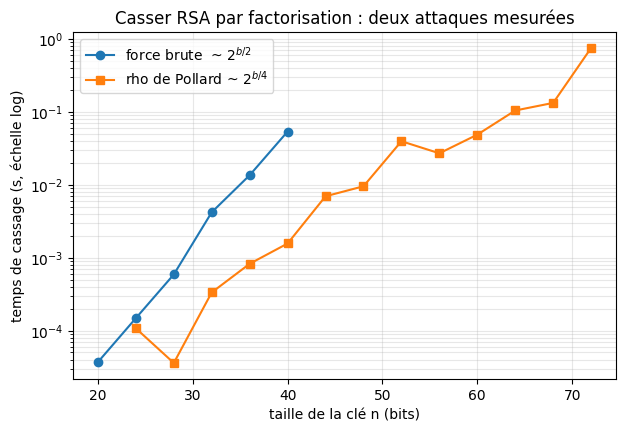

In [6]:
import matplotlib.pyplot as plt
import math

xb = [b for b, _ in mesures_brute]
yb = [max(t, 1e-6) for _, t in mesures_brute]
xr = [b for b, _ in mesures_rho]
yr = [max(t, 1e-6) for _, t in mesures_rho]

plt.figure(figsize=(7, 4.5))
plt.plot(xb, yb, "o-", label="force brute  ~ $2^{b/2}$")
plt.plot(xr, yr, "s-", label="rho de Pollard ~ $2^{b/4}$")
plt.yscale("log")
plt.xlabel("taille de la clé n (bits)")
plt.ylabel("temps de cassage (s, échelle log)")
plt.title("Casser RSA par factorisation : deux attaques mesurées")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### 4.3 Extrapolation : où est la frontière ?

Sur l'échelle logarithmique, les mesures du rho de Pollard s'alignent sur une
droite : le temps suit bien une loi en $2^{b/4}$. On ajuste cette droite et on
l'extrapole (avec prudence — c'est *notre* machine, *notre* implémentation Python,
et le rho reste probabiliste) pour estimer la taille à partir de laquelle l'attaque
dépasse un jour, puis un an.

In [7]:
# ajustement linéaire sur log2(temps) = pente * bits + ordonnée
xs = [b for b, t in mesures_rho if t > 1e-3]     # on ignore les temps trop courts (bruit)
logs = [math.log2(t) for b, t in mesures_rho if t > 1e-3]
m = len(xs)
pente = (m * sum(x * y for x, y in zip(xs, logs)) - sum(xs) * sum(logs)) \
        / (m * sum(x * x for x in xs) - sum(xs) ** 2)
ordonnee = (sum(logs) - pente * sum(xs)) / m
print(f"pente mesurée : {pente:.3f} (théorie : 0,25) | ordonnée à l'origine : {ordonnee:.1f}")

def estimation_secondes(bits):
    return 2 ** (pente * bits + ordonnee)

JOUR, AN = 24 * 3600, 365.25 * 24 * 3600
for bits in (80, 96, 112, 128, 256, 2048):
    t = estimation_secondes(bits)
    if t < JOUR:
        joli = f"{t:.2g} s"
    elif t < AN:
        joli = f"{t / JOUR:.2g} jours"
    elif t < 1e13 * AN:
        joli = f"{t / AN:.2g} ans"
    else:
        joli = f"10^{int(math.log10(t / AN))} ans"
    print(f"clé {bits:>5} bits : ~ {joli}")

pente mesurée : 0.232 (théorie : 0,25) | ordonnée à l'origine : -17.9
clé    80 bits : ~ 1.6 s
clé    96 bits : ~ 21 s
clé   112 bits : ~ 2.7e+02 s
clé   128 bits : ~ 3.5e+03 s
clé   256 bits : ~ 9.3e+04 ans
clé  2048 bits : ~ 10^129 ans


La pente mesurée colle à la théorie ($2^{b/4}$, soit 0,25 bit de temps par bit de
clé). L'extrapolation donne la **frontière expérimentale** : avec cette
implémentation Python, une clé dépasse le jour de calcul autour de 100–110 bits,
et l'année peu après. Autrement dit, une clé RSA « jouet » de 64 bits — qui
paraissait déjà énorme quand on génère les premiers — se casse en quelques
secondes, et il faut monter au-delà de 128 bits pour être tranquille face *au rho
de Pollard seul*. Les vraies attaques (crible algébrique général) sont bien plus
rapides encore : c'est pour cela que les clés réelles font 2048 bits. Le résultat
que personne ne nous avait donné d'avance est dans le tableau ci-dessus : il sort
de nos mesures, pas d'un cours.

### 4.4 Le cas où tout s'effondre : Fermat, ou le danger des premiers trop proches

Si $p$ et $q$ sont **proches**, alors $n = pq$ est proche d'un carré parfait :
avec $a = (p+q)/2$ et $b = (p-q)/2$, on a $n = a^2 - b^2$. La méthode de Fermat
part de $a = \lceil \sqrt{n} \, \rceil$ et cherche $a^2 - n$ carré — elle
converge en $|p - q|/2$ pas environ. Une mauvaise génération de clés (premiers
voisins) rend donc RSA instantané **quelle que soit la taille de la clé**.

In [8]:
def factoriser_fermat(n, pas_max=10_000_000):
    """Factorise n = pq quand p et q sont proches. Renvoie None si trop lents."""
    a = math.isqrt(n)
    if a * a < n:
        a += 1
    for _ in range(pas_max):
        b2 = a * a - n
        b = math.isqrt(b2)
        if b * b == b2:
            return a - b
        a += 1
    return None

# une clé de 128 bits générée avec deux premiers volontairement voisins
random.seed(555)
p = generer_premier(64)
q = p + 2
while not miller_rabin(q):
    q += 2
n = p * q
print(f"n de {n.bit_length()} bits, |p - q| = {q - p}")

debut = time.perf_counter()
facteur = factoriser_fermat(n)
t = time.perf_counter() - debut
print(f"Fermat : facteur trouvé en {t*1000:.2f} ms ->", facteur == p)

# la même taille, mais premiers quelconques : Fermat ne termine plus
pub, priv, p2, q2 = generer_cles(64, e=65537)
debut = time.perf_counter()
res = factoriser_fermat(pub[1], pas_max=200_000)
t = time.perf_counter() - debut
print(f"premiers quelconques ({abs(p2-q2).bit_length()} bits d'écart) : "
      f"{'pas trouvé' if res is None else 'trouvé'} après {t:.2f} s et 200 000 pas")

n de 128 bits, |p - q| = 24
Fermat : facteur trouvé en 0.06 ms -> True
premiers quelconques (31 bits d'écart) : pas trouvé après 0.07 s et 200 000 pas


## 5. Ce qu'on retient

| Taille de clé | Force brute | Rho de Pollard (mesuré/extrapolé) |
|---|---|---|
| 32 bits | instantané | instantané |
| 64 bits | minutes à heures | secondes |
| ~100–128 bits | hors de portée | du jour à l'année (frontière expérimentale) |
| 2048 bits (réel) | — | $10^{\text{centaines}}$ d'années |

Le tableau mélange mesures directes (petites tailles) et extrapolation de la loi
en $2^{b/4}$ (grandes tailles) : la frontière « un jour de calcul » vers 100–110
bits est le résultat central du projet, obtenu par le code et discuté ici.

## 6. Limites et regard critique

Ce qui a été **vérifié par le code** : correction de chaque brique contre une
référence indépendante (`pow`, `math.gcd`, le crible) ; aller-retour
chiffrement/déchiffrement sur 2000 messages aléatoires et un texte accentué ;
cassage effectif de clés jusqu'à 72 bits ; loi de croissance des deux attaques ;
attaque de Fermat sur des premiers voisins.

Ce qu'il faut reconnaître honnêtement :

- **L'extrapolation est fragile.** La droite est ajustée sur des temps de
  quelques secondes en Python pur ; un C compilé, plusieurs cœurs, ou une
  meilleure constante déplacent la frontière. Elle donne un *ordre de grandeur*,
  pas une garantie.
- **Le rho de Pollard n'est pas l'état de l'art.** Le crible algébrique général
  casse des clés bien plus grandes (RSA-250, 829 bits, a été factorisée en 2020).
  Notre « frontière » est celle de *notre* attaque, pas celle de la cryptographie.
- **Ce RSA est du manuel scolaire.** Pas de *padding* (le chiffrement est
  déterministe : deux messages égaux donnent deux chiffrés égaux, et un petit
  message comme « oui » se devine en chiffrant les candidats), messages limités à
  un bloc $< n$, aucune protection contre les attaques par canaux auxiliaires
  (temps d'exécution, cache). Ne jamais utiliser ce code pour chiffrer quoi que
  ce soit de réel.
- **Miller-Rabin reste probabiliste** ; avec 16 témoins la probabilité d'erreur
  est sous $4^{-16} \approx 2\times10^{-10}$ par nombre testé, jugée acceptable
  ici — mais elle existe.
- **Piste non aboutie** : une première version mesurait le temps moyen du rho sans
  graine aléatoire fixe ; les temps variaient d'un facteur 100 entre deux lancers
  sur la même clé (la méthode est probabiliste). Fixer la graine et répéter les
  mesures a rendu la droite d'extrapolation exploitable — c'est ce qui explique
  le filtrage des temps sous 1 ms dans l'ajustement.

## 7. Pour aller plus loin

- Implémenter le crible quadratique et refaire la même extrapolation ;
- Mesurer l'effet du nombre de témoins de Miller-Rabin sur le taux de faux
  premiers (carmichaels) ;
- Découper les messages en blocs et ajouter un padding OAEP simplifié.